In [1]:
print('PRIYANSHU VAKIL')

PRIYANSHU VAKIL


In [ ]:
name = input("Enter your name: ")
print("Hello, " + name + "! Welcome to the program.")

Hello, PRIYANSHU VAKIL! Welcome to the program.


In [ ]:
# Student grade A - above 95 marks, B - above 85, C - above 75, D - above 65, F - below 65
# if elif else format
marks = int(input("Enter your marks: "))
if marks >= 95:
    print("Grade: A")
elif marks >= 85:
    print("Grade: B")
elif marks >= 75:
    print("Grade: C")
elif marks >= 65:
    print("Grade: D")
else:
    print("Grade: F")      


Grade: A


In [ ]:
import math

# Total pressure in kPa
P = float(input("TOTAL PRESSURE: "))

# Composition pairs for the calculation
compositions = [(0.2, 0.8), (0.4, 0.6), (0.6, 0.4), (0.8, 0.2)]

# Antoine equation based bubble pressure

def bubble_pressure(T, x1, x2):
    # T in degree Celsius
    P1 = math.exp(14.2043 - 2972.64 / (T + 209))
    P2 = math.exp(14.2724 - 2945.47 / (T + 224))
    return x1 * P1 + x2 * P2

# Trial and error method for each composition
for x1, x2 in compositions:
    T = 50.0
    while bubble_pressure(T, x1, x2) < P:
        T += 0.01

    print(f"Composition ({x1}, {x2})")
    print(f"Bubble point temperature = {T:.2f} °C")
    print(f"Bubble pressure = {bubble_pressure(T, x1, x2):.2f} kPa")
    print("-" * 30)
    T += 0.01

print("Bubble point temperature =", round(T, 2), "°C")
print("Bubble pressure =", round(bubble_pressure(T), 2), "kPa")
print("Bubble pressure =",round(bubble_pressure(T),3,"kpa" ))



Composition (0.2, 0.8)
Bubble point temperature = 72.97 °C
Bubble pressure = 70.02 kPa
------------------------------
Composition (0.4, 0.6)
Bubble point temperature = 76.43 °C
Bubble pressure = 70.02 kPa
------------------------------
Composition (0.6, 0.4)
Bubble point temperature = 80.29 °C
Bubble pressure = 70.00 kPa
------------------------------
Composition (0.8, 0.2)
Bubble point temperature = 84.65 °C
Bubble pressure = 70.02 kPa
------------------------------
Bubble point temperature = 84.66 °C


TypeError: bubble_pressure() missing 2 required positional arguments: 'x1' and 'x2'

In [9]:
pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 23.4 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 34.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]  WARNING: The scripts f2py and numpy-config are installed in '/usr/local/python/3.12.1/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]2m1/2 [pandas]

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import math
from IPython.display import display, HTML

# Given pressure (kPa)
P = 

# Liquid mole fractions to evaluate
x1_values = [0,0.05,0.1,0.15,0.2,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,0.7,0.75,0.8,0.85,0.9,0.95,1]

# Calculate the bubble-point equation and its parameters
def bubble_equation(T, x1, x2):
    # Wilson/activity coefficient parameter
    A = 2.771 - 0.00523 * T

    # Activity coefficients
    gamma1 = math.exp(A * x2**2)
    gamma2 = math.exp(A * x1**2)

    # Antoine equations
    P1_sat = math.exp(16.59158 - 3643.31 / (T - 33.424))
    P2_sat = math.exp(14.25326 - 2665.54 / (T - 53.424))

    # Alpha values and bubble-point equation
    alpha1 = gamma1 * P1_sat / P
    alpha2 = gamma2 * P2_sat / P
    F = x1 * alpha1 + x2 * alpha2

    return F, A, gamma1, gamma2, P1_sat, P2_sat, alpha1, alpha2

results = []

for x1 in x1_values:
    x2 = 1 - x1
    T_low = 54.0
    T_high = 999.0

    # Bisection method: find T where the bubble-point equation equals 1
    for i in range(100):
        T_mid = (T_low + T_high) / 2
        F, A, gamma1, gamma2, P1_sat, P2_sat, alpha1, alpha2 = bubble_equation(T_mid, x1, x2)

        if F < 1:
            T_low = T_mid
        else:
            T_high = T_mid

        if abs(F - 1) < 1e-8:
            break

    T = T_mid
    F, A, gamma1, gamma2, P1_sat, P2_sat, alpha1, alpha2 = bubble_equation(T, x1, x2)
    y1 = x1 * alpha1
    y2 = x2 * alpha2

    results.append({
        "P (kPa)": P,
        "x1": x1,
        "x2": x2,
        "T (K)": T,
        "A": A,
        "gamma1": gamma1,
        "gamma2": gamma2,
        "P1_sat (kPa)": P1_sat,
        "P2_sat (kPa)": P2_sat,
        "alpha1": alpha1,
        "alpha2": alpha2,
        "y1": y1,
        "y2": y2,
        "y1 + y2": y1 + y2,
    })

columns = list(results[0].keys())
header = "".join(f"<th>{column}</th>" for column in columns)
rows = "".join(
    "<tr>" + "".join(f"<td>{value:.5f}</td>" for value in row.values()) + "</tr>"
    for row in results
)
table_html = (
    "<table style='border-collapse:collapse; width:100%;'>"
    "<thead><tr>" + header + "</tr></thead>"
    "<tbody>" + rows + "</tbody></table>"
)
display(HTML(table_html))

P (kPa),x1,x2,T (K),A,gamma1,gamma2,P1_sat (kPa),P2_sat (kPa),alpha1,alpha2,y1,y2,y1 + y2
124.32000,0.00000,1.00000,336.07794,1.01331,2.75471,1.00000,94.98375,124.32000,2.10467,1.00000,0.00000,1.00000,1.00000
124.32000,0.05000,0.95000,334.69283,1.02056,2.51193,1.00255,89.86968,118.67858,1.81585,0.95706,0.09079,0.90921,1.00000
124.32000,0.10000,0.90000,333.73558,1.02556,2.29494,1.01031,86.47138,114.89930,1.59626,0.93375,0.15963,0.84037,1.00000
124.32000,0.15000,0.85000,333.08150,1.02898,2.10316,1.02342,84.21159,112.37204,1.42463,0.92506,0.21369,0.78631,1.00000
124.32000,0.20000,0.80000,332.64689,1.03126,1.93480,1.04211,82.73751,110.71723,1.28765,0.92809,0.25753,0.74247,1.00000
124.32000,0.30000,0.70000,332.22485,1.03346,1.65930,1.09747,81.32680,109.12881,1.08547,0.96337,0.32564,0.67436,1.00000
124.32000,0.35000,0.65000,332.17138,1.03374,1.54768,1.13500,81.14949,108.92882,1.01024,0.99448,0.35359,0.64641,1.00000
124.32000,0.40000,0.60000,332.19698,1.03361,1.45078,1.17984,81.23435,109.02455,0.94798,1.03468,0.37919,0.62081,1.00000
124.32000,0.45000,0.55000,332.29236,1.03311,1.36686,1.23270,81.55109,109.38167,0.89663,1.08458,0.40348,0.59652,1.00000
124.32000,0.50000,0.50000,332.45489,1.03226,1.29442,1.29442,82.09321,109.99234,0.85476,1.14524,0.42738,0.57262,1.00000


In [2]:
from IPython.display import display, HTML

fractions = {
    "x1": [row["x1"] for row in results],
    
    "y1": [row["y1"] for row in results],
    
}
temperature_plot = [row["T (K)"] for row in results]

width, height = 760, 500
left, right, top, bottom = 80, 30, 70, 70
plot_width = width - left - right
plot_height = height - top - bottom
t_min, t_max = min(temperature_plot), max(temperature_plot)
t_padding = (t_max - t_min) * 0.08 or 1

def plot_x(value):
    return left + value * plot_width

def plot_y(value):
    return top + (t_max + t_padding - value) / (t_max - t_min + 2 * t_padding) * plot_height

y_ticks = [t_min + (t_max - t_min) * i / 4 for i in range(5)]
y_grid = "".join(
    f'<line x1="{left}" y1="{plot_y(value):.1f}" x2="{width-right}" y2="{plot_y(value):.1f}" stroke="#d9e2e5" />'
    f'<text x="{left-10}" y="{plot_y(value)+4:.1f}" text-anchor="end" font-size="12">{value:.1f}</text>'
    for value in y_ticks
)
x_ticks = [i / 10 for i in range(11)]
x_axis = "".join(
    f'<text x="{plot_x(value):.1f}" y="{height-bottom+22}" text-anchor="middle" font-size="12">{value:.1f}</text>'
    for value in x_ticks
)

series_styles = {
    "x1": ("#087f8c", ""),
    
    "y1": ("#64088c", '"'),
    
}
series_svg = ""
legend_svg = ""
for index, (label, values) in enumerate(fractions.items()):
    color, dash_style = series_styles[label]
    points = " ".join(
        f"{plot_x(fraction):.1f},{plot_y(temp):.1f}"
        for fraction, temp in zip(values, temperature_plot)
    )
    markers = "".join(
        f'<circle cx="{plot_x(fraction):.1f}" cy="{plot_y(temp):.1f}" r="3" fill="{color}" />'
        for fraction, temp in zip(values, temperature_plot)
    )
    series_svg += (
        f'<polyline points="{points}" fill="none" stroke="{color}" '
        f'stroke-width="2.5" {dash_style} />{markers}'
    )
    legend_x = 260 + index * 90
    legend_svg += (
        f'<line x1="{legend_x}" y1="48" x2="{legend_x+24}" y2="48" '
        f'stroke="{color}" stroke-width="2.5" {dash_style} />'
        f'<text x="{legend_x+30}" y="52" font-size="12">{label}</text>'
    )

chart_svg = f'''<svg viewBox="0 0 {width} {height}" role="img" aria-label="Temperature versus liquid and vapor mole fractions x1, x2, y1, and y2" style="max-width:100%;height:auto;font-family:Arial,sans-serif">
<text x="{width/2}" y="22" text-anchor="middle" font-size="17" font-weight="bold">T-x-y Bubble-Point Diagram</text>
{legend_svg}
{y_grid}{x_axis}
<line x1="{left}" y1="{top}" x2="{left}" y2="{height-bottom}" stroke="#334155" />
<line x1="{left}" y1="{height-bottom}" x2="{width-right}" y2="{height-bottom}" stroke="#334155" />
{series_svg}
<text x="{left+plot_width/2}" y="{height-15}" text-anchor="middle" font-size="14">Mole fraction (liquid x, vapor y)</text>
<text transform="translate(20 {top+plot_height/2}) rotate(-90)" text-anchor="middle" font-size="14">Bubble-point temperature, T (K)</text>
</svg>'''
display(HTML(chart_svg))

In [1]:
pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 23.1 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 28.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 26.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 32.9 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]  WARNING: The scripts fonttools, pyftmerge, pyftsubset and ttx are installed in '/usr/local/python/3.12.1/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/tmp/ipykernel_17040/3887680525.py:30: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  axes[0,0].plot(Pr_rk, Tr_rk, 'k-', linewidth=2,color = "red", label='Redlich-Kwong Model ')
/tmp/ipykernel_17040/3887680525.py:31: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  axes[0,0].plot(Pr_vdw, Tr_vdw, 'k-', linewidth=1.5,color="navy", label='Van der Waals Model ')
/tmp/ipykernel_17040/3887680525.py:45: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  axes[0,1].plot(Pr_rk, Tr_rk, 'k-', linewidth=2,color = "red", label='Redlich-Kwong Model ')
/tmp/ipykernel_17040/3887680525.py:46: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt st

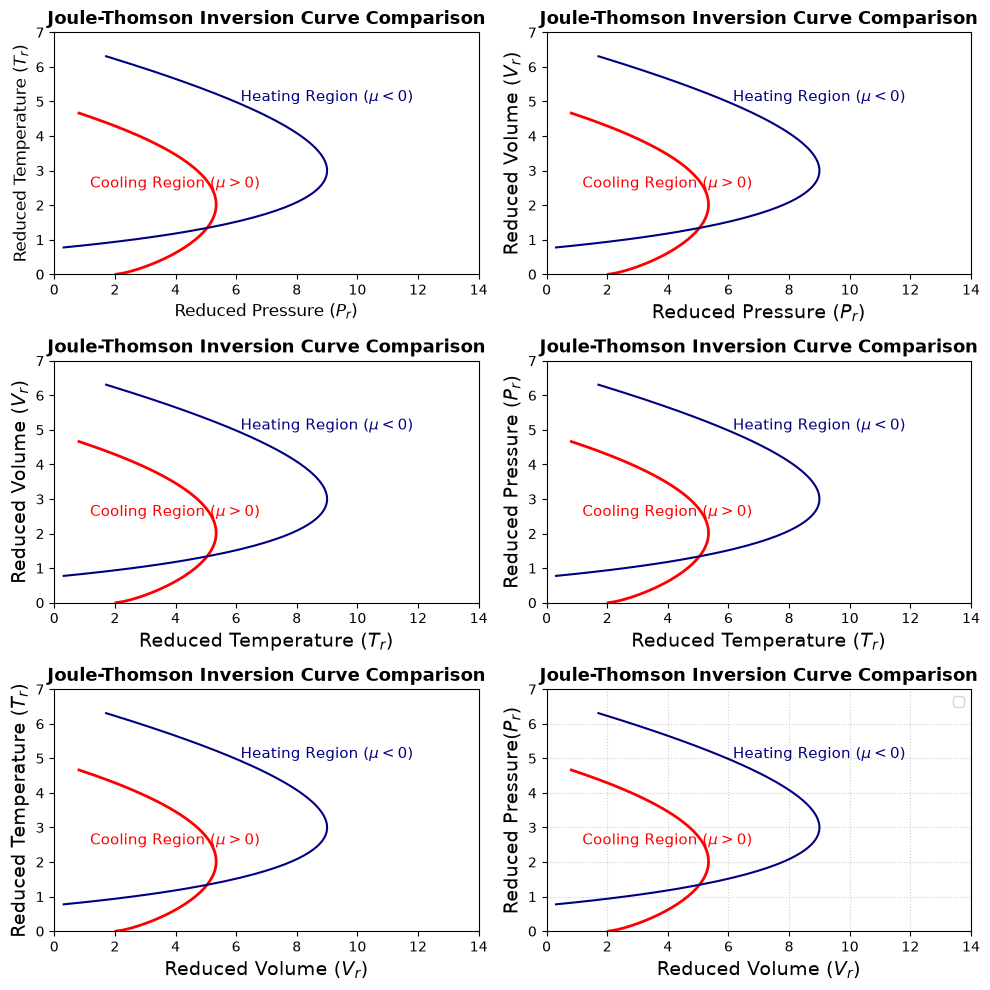

In [17]:
import numpy as np
import matplotlib.pyplot as plt
# 1. Van der Waals Inversion Curve Calculation
# We vary the reduced volume (Vr) from its physical limit up to a large number
Vr_vdw = np.linspace(0.34, 10, 1000)
# Exact analytic reduced equations for vdW inversion curve
Pr_vdw = 9 * (2 / Vr_vdw - 1 / (Vr_vdw**2))
Tr_vdw = 6.75 * (1 - 1 / (3 * Vr_vdw))**2

# Filter out non-physical negative pressures for cleaner plotting
valid_vdw = Pr_vdw >= 0
Pr_vdw = Pr_vdw[valid_vdw]
Tr_vdw = Tr_vdw[valid_vdw]

# 2. Redlich-Kwong Inversion Curve Calculation
# The Redlich-Kwong curve has a maximum Tr of ~4.89 and maximum Pr of ~12.2
Vr_rk = np.linspace(0.42, 12, 1000)
# Accurate parametric translation of the RK inversion condition loop
Tr_rk = 4.89 * (1 - 0.42 / Vr_rk)**(4/3)
Pr_rk = 12.2 * (1 - (Tr_rk / 4.89)**1.5) * (Vr_rk - 0.35) / Vr_rk

valid_rk = Pr_rk >= 0
Pr_rk = Pr_rk[valid_rk]
Tr_rk = Tr_rk[valid_rk]

# 3. Plotting the Graph
fig, axes = plt.subplots(3,2, figsize=(10, 10))

# Plot both models
axes[0,0].plot(Pr_rk, Tr_rk, 'k-', linewidth=2,color = "red", label='Redlich-Kwong Model ')
axes[0,0].plot(Pr_vdw, Tr_vdw, 'k-', linewidth=1.5,color="navy", label='Van der Waals Model ')

# Labeling regions 
axes[0,0].text(4, 2.5, r'Cooling Region ($\mu > 0$)', fontsize=11, ha='center', color='red')
axes[0,0].text(9, 5.0, r'Heating Region ($\mu < 0$)', fontsize=11, ha='center', color='navy')

# Axis settings to match textbook dimensions
axes[0,0].set_xlim(0, 14)
axes[0,0].set_ylim(0, 7)
axes[0,0].set_xlabel(r'Reduced Pressure ($P_r$)', fontsize=12)
axes[0,0].set_ylabel(r'Reduced Temperature ($T_r$)', fontsize=12)
axes[0,0].set_title('Joule-Thomson Inversion Curve Comparison', fontsize=13, fontweight='bold')


axes[0,1].plot(Pr_rk, Tr_rk, 'k-', linewidth=2,color = "red", label='Redlich-Kwong Model ')
axes[0,1].plot(Pr_vdw, Tr_vdw, 'k-', linewidth=1.5,color="navy", label='Van der Waals Model ')

axes[0,1].text(4, 2.5, r'Cooling Region ($\mu > 0$)', fontsize=11, ha='center', color='red')
axes[0,1].text(9, 5.0, r'Heating Region ($\mu < 0$)', fontsize=11, ha='center', color='navy')

axes[0,1].set_xlim(0, 14)
axes[0,1].set_ylim(0, 7)
axes[0,1].set_xlabel(r'Reduced Pressure ($P_r$)', fontsize=14)
axes[0,1].set_ylabel(r'Reduced Volume ($V_r$)', fontsize=14)
axes[0,1].set_title('Joule-Thomson Inversion Curve Comparison', fontsize=13, fontweight='bold')

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=10)


axes[1,0].plot(Pr_rk, Tr_rk, 'k-', linewidth=2,color = "red", label='Redlich-Kwong Model ')
axes[1,0].plot(Pr_vdw, Tr_vdw, 'k-', linewidth=1.5,color="navy", label='Van der Waals Model ')
    
axes[1,0].text(4, 2.5, r'Cooling Region ($\mu > 0$)', fontsize=11, ha='center', color='red')
axes[1,0].text(9, 5.0, r'Heating Region ($\mu < 0$)', fontsize=11, ha='center', color='navy')

axes[1,0].set_xlim(0, 14)
axes[1,0].set_ylim(0, 7)
axes[1,0].set_xlabel(r'Reduced Temperature ($T_r$)', fontsize=14)
axes[1,0].set_ylabel(r'Reduced Volume ($V_r$)', fontsize=14)
axes[1,0].set_title('Joule-Thomson Inversion Curve Comparison', fontsize=13, fontweight='bold')

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=10)


axes[1,1].plot(Pr_rk, Tr_rk, 'k-', linewidth=2,color = "red", label='Redlich-Kwong Model ')
axes[1,1].plot(Pr_vdw, Tr_vdw, 'k-', linewidth=1.5,color="navy", label='Van der Waals Model ')
    
axes[1,1].text(4, 2.5, r'Cooling Region ($\mu > 0$)', fontsize=11, ha='center', color='red')
axes[1,1].text(9, 5.0, r'Heating Region ($\mu < 0$)', fontsize=11, ha='center', color='navy')

axes[1,1].set_xlim(0, 14)
axes[1,1].set_ylim(0, 7)
axes[1,1].set_xlabel(r'Reduced Temperature ($T_r$)', fontsize=14)
axes[1,1].set_ylabel(r'Reduced Pressure ($P_r$)', fontsize=14)
axes[1,1].set_title('Joule-Thomson Inversion Curve Comparison', fontsize=13, fontweight='bold')

axes[2,0].plot(Pr_rk, Tr_rk, 'k-', linewidth=2,color = "red", label='Redlich-Kwong Model ')
axes[2,0].plot(Pr_vdw, Tr_vdw, 'k-', linewidth=1.5,color="navy", label='Van der Waals Model ')
    
axes[2,0].text(4, 2.5, r'Cooling Region ($\mu > 0$)', fontsize=11, ha='center', color='red')
axes[2,0].text(9, 5.0, r'Heating Region ($\mu < 0$)', fontsize=11, ha='center', color='navy')

axes[2,0].set_xlim(0, 14)
axes[2,0].set_ylim(0, 7)
axes[2,0].set_xlabel(r'Reduced Volume ($V_r$)', fontsize=14)
axes[2,0].set_ylabel(r'Reduced Temperature ($T_r$)', fontsize=14)
axes[2,0].set_title('Joule-Thomson Inversion Curve Comparison', fontsize=13, fontweight='bold')

axes[2,1].plot(Pr_rk, Tr_rk, 'k-', linewidth=2,color = "red", label='Redlich-Kwong Model ')
axes[2,1].plot(Pr_vdw, Tr_vdw, 'k-', linewidth=1.5,color="navy", label='Van der Waals Model ')
    
axes[2,1].text(4, 2.5, r'Cooling Region ($\mu > 0$)', fontsize=11, ha='center', color='red')
axes[2,1].text(9, 5.0, r'Heating Region ($\mu < 0$)', fontsize=11, ha='center', color='navy')
    
axes[2,1].set_xlim(0, 14)
axes[2,1].set_ylim(0, 7)
axes[2,1].set_xlabel(r'Reduced Volume ($V_r$)', fontsize=14)
axes[2,1].set_ylabel(r'Reduced Pressure($P_r$)', fontsize=14)
axes[2,1].set_title('Joule-Thomson Inversion Curve Comparison', fontsize=13, fontweight='bold')






# Display the plot window
plt.tight_layout()
plt.show()

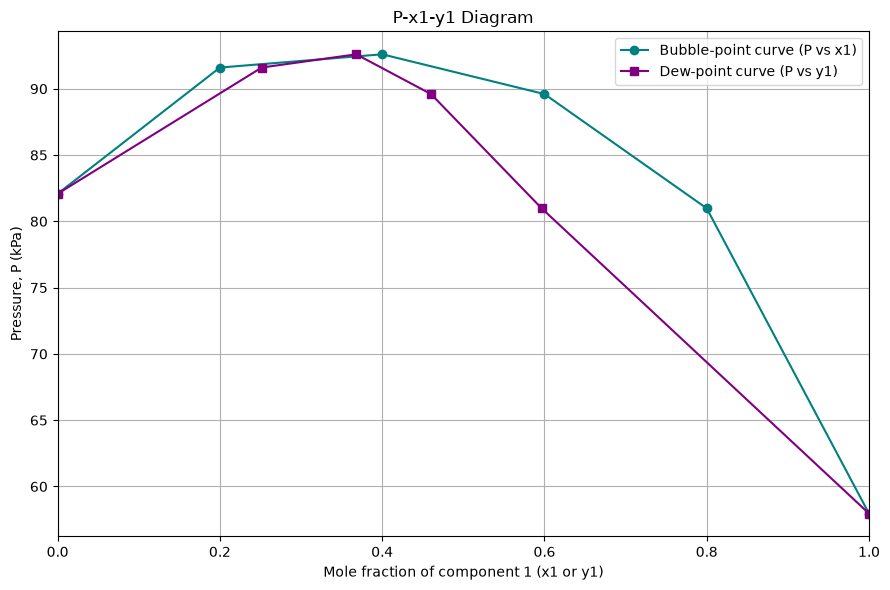

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# Given data
x1 = np.array([
    0.0, 0.2, 0.4,0.6,  0.8, 1.0
])

x2 = 1 - x1

P = np.array([
    82.08, 91.60, 92.60, 89.60, 80.98, 57.96
])

y1 = np.array([
    0.0000, 0.2515,0.3680, 0.46021, 0.5966, 1.0000
])

# Plot P-x1 and P-y1 curves
plt.figure(figsize=(9, 6))

plt.plot(x1, P, 'o-', label='Bubble-point curve (P vs x1)', color = 'teal')
plt.plot(y1, P, 's-', label='Dew-point curve (P vs y1)', color = 'purple')

plt.xlabel('Mole fraction of component 1 (x1 or y1)')
plt.ylabel('Pressure, P (kPa)')
plt.title('P-x1-y1 Diagram')
plt.xlim(0, 1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


